# AMR Fluorescence Pipeline: multi-method cell + nucleoid segmentation

**Cell methods:** `cellpose_omni` (bact_fluor_omni), `marker_watershed`, `adaptive_morphology`
**Nucleoid methods:** `masked_otsu`, `masked_watershed`, `blob_log`

Every image is loaded once. Every cell method is run on it, and every nucleoid method is then run on each cell method's mask.
Outputs are stored **method-wise**: masks, individual-cell images, nucleoid crops, overlays and CSVs each get their own per-method folder.

Quantitative values (intensity, GLCM, nucleoid stats) come from **raw** pixel values. Enhanced (CLAHE) images are for visualization / ML input only.

## 0. Setup: install, mount Drive, unzip data

In [1]:
!pip install --quiet tifffile "cellpose<4" scikit-image scipy tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.9/204.9 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.4/7.4 MB 44.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.1/28.1 MB 31.2 MB/s eta 0:00:00


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

RAW_DIR = "/content/dataset_raw"
os.makedirs(RAW_DIR, exist_ok=True)

zip_path = '/content/drive/MyDrive/HRG Projects/Research/zagajewski_data_files.zip'

if os.path.exists(zip_path):
    if not os.listdir(RAW_DIR):          # avoid re-extracting on re-runs
        !unzip -q "{zip_path}" -d "{RAW_DIR}"
    print(f"Data ready in {RAW_DIR}")
else:
    print(f"Error: Zip file not found at {zip_path}")

Data ready in /content/dataset_raw


## 1. Imports

In [4]:
import json
import math
import random
import shutil
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tifffile
import torch
from PIL import Image
from tqdm.auto import tqdm

from scipy import ndimage as ndi
from scipy.optimize import linear_sum_assignment
from skimage import draw
from skimage.exposure import equalize_adapthist
from skimage.feature import blob_log, graycomatrix, graycoprops, peak_local_max
from skimage.filters import threshold_local, threshold_otsu, unsharp_mask
from skimage.measure import label, regionprops
from skimage.morphology import disk
from skimage.segmentation import find_boundaries, relabel_sequential, watershed

from cellpose import models

warnings.filterwarnings("ignore")

## 2. Configuration (all tunable settings live here)

In [5]:
# ---------------- Paths ----------------
INPUT_DIR        = Path("/content/dataset_raw/Mini AMR")   # contains one sub-folder per treatment class
OUTPUT_DIR       = Path("/content/outputs")
GROUND_TRUTH_DIR = Path("/content/ground_truth")           # optional: GT/<class>/<image_name>.tif (instance masks)

# ---------------- Dataset ----------------
CLASSES = ["CIP+ETOH", "RIF+ETOH", "GENT+ETOH", "COAMOX+ETOH", "WT+ETOH"]
PIXEL_SIZE_UM = 0.065           # micrometres per pixel (microscope calibration)
MAX_IMAGES_PER_CLASS = None     # e.g. 3 for a quick test run; None = all images
SEED = 42

# ---------------- Methods ----------------
CELL_METHODS = ["cellpose_omni", "marker_watershed", "adaptive_morphology"]
NUC_METHODS  = ["masked_otsu", "masked_watershed", "blob_log"]
NUC_PREFIX   = {"masked_otsu": "Otsu", "masked_watershed": "Watershed", "blob_log": "BlobLoG"}  # CSV column prefixes

# ---------------- cellpose_omni ----------------
OMNI_MODEL_NAME     = "bact_fluor_cp3"
OMNI_USE_DNA_CHANNEL = False    # False: membrane channel only. True: feed [membrane, DNA] as 2 channels
OMNI_MIN_SIZE       = 15
OMNI_MASK_THRESHOLD = 0.0
OMNI_FLOW_THRESHOLD = 0.4

# ---------------- Filtering / measurement ----------------
MIN_CELL_AREA_PX = 20           # applied to every cell method
NUC_MIN_AREA_PX  = 10           # applied to every nucleoid method
GLCM_LEVELS      = 32           # grey levels for texture features (background excluded)

# ---------------- Exports ----------------
CROP_MARGIN          = 4        # px of context around each individual cell image
SAVE_CELL_IMAGES     = True     # per-cell PNG (enhanced RGB) + TIFF (raw 2-channel)
SAVE_NUCLEOID_CROPS  = False     # per-nucleoid raw crops (many files: set False to shrink the ZIP)
SAVE_OVERLAYS        = True     # per-image QC overlay of cell outlines

# ---------------- Evaluation (needs GT instance masks) ----------------
IOU_THRESHOLDS = [round(x, 2) for x in np.arange(0.50, 1.00, 0.05)]
PRIMARY_IOU_THRESHOLD = 0.80

random.seed(SEED)
np.random.seed(SEED)

## 3. Output folder structure (method-wise)

In [6]:
def make_dirs():
    for cm in CELL_METHODS:
        for c in CLASSES:
            (OUTPUT_DIR / "masks" / "cells" / cm / c).mkdir(parents=True, exist_ok=True)
            (OUTPUT_DIR / "individual_cells" / cm / c).mkdir(parents=True, exist_ok=True)
            for nm in NUC_METHODS:
                (OUTPUT_DIR / "masks" / "nucleoids" / cm / nm / c).mkdir(parents=True, exist_ok=True)
                (OUTPUT_DIR / "individual_nucleoids" / cm / nm / c).mkdir(parents=True, exist_ok=True)
        (OUTPUT_DIR / "overlays" / cm).mkdir(parents=True, exist_ok=True)
    for sub in ["tables", "qc", "metrics", "logs"]:
        (OUTPUT_DIR / sub).mkdir(parents=True, exist_ok=True)

make_dirs()

## 4. Utilities: loading, normalization, mask handling

In [7]:
def load_fluorescence_tiff(path):
    """Return (membrane, dna) as float32 H x W arrays. Accepts C x H x W or H x W x C.
    Channel 0 = Nile Red (membrane), channel 1 = DNA."""
    arr = np.squeeze(tifffile.imread(str(path)))
    if arr.ndim != 3:
        raise ValueError(f"{Path(path).name}: unsupported TIFF shape {arr.shape}")
    if arr.shape[0] <= 8 and arr.shape[1] > 32 and arr.shape[2] > 32:      # channel-first
        arr = np.moveaxis(arr, 0, -1)
    elif not (arr.shape[2] <= 8 and arr.shape[0] > 32 and arr.shape[1] > 32):
        raise ValueError(f"{Path(path).name}: cannot determine channel axis from {arr.shape}")
    return arr[..., 0].astype(np.float32), arr[..., 1].astype(np.float32)


def normalize_channel(ch):
    """Percentile (1-99) normalization to [0, 1]. Used for SEGMENTATION INPUT and display only."""
    p1, p99 = np.percentile(ch, (1, 99))
    denom = p99 - p1 if (p99 - p1) > 0 else 1.0
    return np.clip((ch - p1) / denom, 0.0, 1.0).astype(np.float32)


def clean_labels(labels, min_area):
    """Drop objects smaller than min_area, then relabel 1..N."""
    labels = np.asarray(labels).astype(np.int64)
    if labels.max() == 0:
        return labels.astype(np.uint16)
    areas = np.bincount(labels.ravel())
    small = areas < min_area
    small[0] = False
    labels = np.where(small[labels], 0, labels)
    labels, _, _ = relabel_sequential(labels)
    return labels.astype(np.uint16 if labels.max() < 65535 else np.uint32)


def save_mask(mask, path):
    dtype = np.uint16 if mask.max() < 65535 else np.uint32
    tifffile.imwrite(str(path), mask.astype(dtype))


def circularity(area, perimeter):
    return float(4.0 * np.pi * area / perimeter ** 2) if perimeter > 0 else np.nan


def enhance_channel(img, mask=None):
    """DISPLAY/ML ONLY: percentile stretch (inside mask) + CLAHE + mild sharpening."""
    img = img.astype(np.float32)
    vals = img[mask] if mask is not None and mask.any() else img
    p1, p99 = np.percentile(vals, (1, 99))
    if p99 <= p1:
        p99 = p1 + 1.0
    img = np.clip((img - p1) / (p99 - p1), 0, 1)
    img = equalize_adapthist(img, kernel_size=None, clip_limit=0.02)
    img = unsharp_mask(img, radius=1.0, amount=0.5)
    return np.clip(img, 0, 1).astype(np.float32)

## 5. Device check & cellpose_omni model

In [8]:
use_gpu = torch.cuda.is_available()
print(f"[Device Check] GPU Available: {use_gpu}")
if use_gpu:
    print(f"Device Name: {torch.cuda.get_device_name(0)}")

omni_model = None
if "cellpose_omni" in CELL_METHODS:
    omni_model = models.CellposeModel(gpu=use_gpu, model_type=OMNI_MODEL_NAME)
    print(f"Loaded cellpose_omni model: {OMNI_MODEL_NAME}")

[Device Check] GPU Available: True
Device Name: Tesla T4


100%|██████████| 25.3M/25.3M [00:02<00:00, 9.99MB/s]


Loaded cellpose_omni model: bact_fluor_cp3


## 6. Cell segmentation methods
Each takes `(membrane_norm, dna_norm)` and returns a labelled mask.

### 6a. cellpose_omni (`bact_fluor_omni`)

In [9]:
def segment_cells_cellpose_omni(membrane_norm, dna_norm):
    if OMNI_USE_DNA_CHANNEL:
        img, channels = np.stack([membrane_norm, dna_norm], axis=-1), [1, 2]
    else:
        img, channels = membrane_norm, [0, 0]
    masks, _, _ = omni_model.eval(
        img,
        channels=channels,
        min_size=OMNI_MIN_SIZE,
        diameter=30,
        flow_threshold=OMNI_FLOW_THRESHOLD
    )
    return masks

### 6b. Marker-controlled watershed

In [10]:
def segment_cells_watershed(membrane_norm, dna_norm=None):
    thresh = threshold_otsu(membrane_norm)
    binary = ndi.binary_closing(membrane_norm > thresh, structure=disk(2))
    distance = ndi.distance_transform_edt(binary)
    coords = peak_local_max(distance, min_distance=7, labels=binary.astype(int))
    markers = np.zeros(distance.shape, dtype=np.int32)
    if len(coords) > 0:
        markers[tuple(coords.T)] = np.arange(1, len(coords) + 1)
    return watershed(-distance, markers, mask=binary)

### 6c. Adaptive (local-threshold) morphology  
*Does not split touching cells: expect merged objects in dense fields.*

In [11]:
def segment_cells_adaptive(membrane_norm, dna_norm=None):
    local_thresh = threshold_local(membrane_norm, block_size=35, offset=0.02)
    binary = ndi.binary_opening(membrane_norm > local_thresh, structure=disk(1))
    binary = ndi.binary_closing(binary, structure=disk(2))
    return label(binary)


CELL_SEGMENTERS = {
    "cellpose_omni": segment_cells_cellpose_omni,
    "marker_watershed": segment_cells_watershed,
    "adaptive_morphology": segment_cells_adaptive,
}

## 7. Nucleoid segmentation methods
Each takes `(cell_mask, dna_raw, ctx)` and returns a labelled nucleoid mask (nucleoids are restricted to their parent cell). `ctx` caches per-image data (normalized DNA, LoG blobs) so it is computed once, not once per cell method.

In [12]:
def _paste_components(window, labeled, nuc_id, min_area):
    """Copy connected components >= min_area into `window` (a view of the full mask) with unique IDs."""
    if labeled.max() == 0:
        return nuc_id
    areas = np.bincount(labeled.ravel())
    for i in np.nonzero(areas >= min_area)[0]:
        if i == 0:
            continue
        window[labeled == i] = nuc_id
        nuc_id += 1
    return nuc_id

### 7a. Masked Otsu (per cell)

In [13]:
def segment_nucleoids_otsu(cell_mask, dna_raw, ctx):
    nuc_mask = np.zeros(cell_mask.shape, dtype=np.uint32)
    nuc_id = 1
    for prop in regionprops(cell_mask):
        minr, minc, maxr, maxc = prop.bbox
        sub_c = cell_mask[minr:maxr, minc:maxc] == prop.label
        sub_dna = dna_raw[minr:maxr, minc:maxc]
        vals = sub_dna[sub_c]
        if vals.size > 20 and np.ptp(vals) > 0:
            th = threshold_otsu(vals)
            sub_nuc = ndi.binary_opening((sub_dna > th) & sub_c, structure=disk(1))
            nuc_id = _paste_components(nuc_mask[minr:maxr, minc:maxc], label(sub_nuc), nuc_id, NUC_MIN_AREA_PX)
    return nuc_mask

### 7b. Masked watershed (per cell)

In [14]:
def segment_nucleoids_watershed(cell_mask, dna_raw, ctx):
    nuc_mask = np.zeros(cell_mask.shape, dtype=np.uint32)
    nuc_id = 1
    for prop in regionprops(cell_mask):
        minr, minc, maxr, maxc = prop.bbox
        sub_c = cell_mask[minr:maxr, minc:maxc] == prop.label
        sub_dna = dna_raw[minr:maxr, minc:maxc]
        vals = sub_dna[sub_c]
        if vals.size > 20 and np.ptp(vals) > 0:
            th = threshold_otsu(vals)
            bin_nuc = (sub_dna > th) & sub_c
            dist = ndi.distance_transform_edt(bin_nuc)
            coords = peak_local_max(dist, min_distance=3, labels=bin_nuc.astype(int))
            if len(coords) > 0:
                markers = np.zeros(dist.shape, dtype=np.int32)
                markers[tuple(coords.T)] = np.arange(1, len(coords) + 1)
                ws = watershed(-dist, markers, mask=bin_nuc)
                nuc_id = _paste_components(nuc_mask[minr:maxr, minc:maxc], ws, nuc_id, NUC_MIN_AREA_PX)
    return nuc_mask

### 7c. Blob-LoG detection

In [15]:
def segment_nucleoids_blob(cell_mask, dna_raw, ctx):
    if ctx.get("blobs") is None:                       # detect once per image
        ctx["blobs"] = blob_log(ctx["dna_norm"], min_sigma=1, max_sigma=5, num_sigma=5, threshold=0.08)

    nuc_mask = np.zeros(cell_mask.shape, dtype=np.uint32)
    nuc_id = 1
    for b in ctx["blobs"]:
        y, x = int(b[0]), int(b[1])
        r = int(np.ceil(b[2] * np.sqrt(2)))
        if not (0 <= y < cell_mask.shape[0] and 0 <= x < cell_mask.shape[1]):
            continue
        cell_id = cell_mask[y, x]
        if cell_id == 0:
            continue
        rr, cc = draw.disk((y, x), radius=max(r, 2), shape=cell_mask.shape)
        valid = cell_mask[rr, cc] == cell_id            # stay inside the parent cell
        rr, cc = rr[valid], cc[valid]
        free = nuc_mask[rr, cc] == 0                    # do not overwrite earlier nucleoids
        if free.any():
            nuc_mask[rr[free], cc[free]] = nuc_id
            nuc_id += 1
    # apply the same minimum-area rule as the other methods
    return clean_labels(nuc_mask, NUC_MIN_AREA_PX).astype(np.uint32)


NUC_SEGMENTERS = {
    "masked_otsu": segment_nucleoids_otsu,
    "masked_watershed": segment_nucleoids_watershed,
    "blob_log": segment_nucleoids_blob,
}

## 8. Feature extraction + per-cell export helpers
Measurements use **raw** channels. Texture (GLCM) is computed inside the cell only (background excluded).

In [16]:
def glcm_features(sub_memb, sub_cell):
    """GLCM texture inside the cell only. Pixels are quantized to 1..GLCM_LEVELS; 0 = background and is dropped."""
    nan = {"Texture_Contrast": np.nan, "Texture_Correlation": np.nan,
           "Texture_Energy": np.nan, "Texture_Homogeneity": np.nan}
    vals = sub_memb[sub_cell]
    if vals.size < 4 or vals.max() <= vals.min():
        return nan
    lo, hi = vals.min(), vals.max()
    q = np.zeros(sub_memb.shape, dtype=np.uint8)
    q[sub_cell] = 1 + np.floor((vals - lo) / (hi - lo + 1e-6) * (GLCM_LEVELS - 1)).astype(np.uint8)
    glcm = graycomatrix(q, distances=[1], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
                        levels=GLCM_LEVELS + 1, symmetric=True, normed=False)[1:, 1:]
    sums = glcm.sum(axis=(0, 1), keepdims=True).astype(np.float64)
    if sums.sum() == 0:
        return nan
    glcm = glcm / np.where(sums == 0, 1, sums)
    return {
        "Texture_Contrast": float(graycoprops(glcm, "contrast").mean()),
        "Texture_Correlation": float(graycoprops(glcm, "correlation").mean()),
        "Texture_Energy": float(graycoprops(glcm, "energy").mean()),
        "Texture_Homogeneity": float(graycoprops(glcm, "homogeneity").mean()),
    }


def summarize_nucleoids(props, cell_area_px, prefix):
    """Cell-level aggregate of one nucleoid method. Cells with no nucleoid: count/area = 0, shape/intensity = NaN."""
    keys = ["Count", "Total_Area_um2", "Mean_Length_um", "Mean_Width_um", "Mean_Circularity",
            "Mean_Eccentricity", "Mean_DNA_Intensity", "Max_DNA_Intensity", "Cell_Area_Ratio"]
    if len(props) == 0:
        out = {f"{prefix}_{k}": np.nan for k in keys}
        out[f"{prefix}_Count"] = 0
        out[f"{prefix}_Total_Area_um2"] = 0.0
        out[f"{prefix}_Cell_Area_Ratio"] = 0.0
        return out
    total_px = float(sum(p.area for p in props))
    return {
        f"{prefix}_Count": len(props),
        f"{prefix}_Total_Area_um2": total_px * PIXEL_SIZE_UM ** 2,
        f"{prefix}_Mean_Length_um": float(np.mean([p.major_axis_length for p in props])) * PIXEL_SIZE_UM,
        f"{prefix}_Mean_Width_um": float(np.mean([p.minor_axis_length for p in props])) * PIXEL_SIZE_UM,
        f"{prefix}_Mean_Circularity": float(np.nanmean([circularity(p.area, p.perimeter) for p in props])),
        f"{prefix}_Mean_Eccentricity": float(np.mean([p.eccentricity for p in props])),
        f"{prefix}_Mean_DNA_Intensity": float(np.mean([p.mean_intensity for p in props])),
        f"{prefix}_Max_DNA_Intensity": float(np.max([p.max_intensity for p in props])),
        f"{prefix}_Cell_Area_Ratio": total_px / cell_area_px if cell_area_px > 0 else np.nan,
    }


def intensity_stats(px, prefix):
    return {
        f"{prefix}_Mean": float(np.mean(px)), f"{prefix}_Median": float(np.median(px)),
        f"{prefix}_Min": float(np.min(px)), f"{prefix}_Max": float(np.max(px)),
        f"{prefix}_Std": float(np.std(px)), f"{prefix}_Variance": float(np.var(px)),
    }


def measure_and_export_cells(cell_method, treatment, fname, cell_mask, membrane, dna, nuc_masks):
    """Measure every cell of one (image, cell_method), save method-wise crops, return records."""
    H, W = cell_mask.shape
    cell_rows, nuc_rows = [], []

    cell_dir = OUTPUT_DIR / "individual_cells" / cell_method / treatment

    for cell in regionprops(cell_mask):
        cid = cell.label
        cell_uid = f"{fname}_cell_{cid}"
        minr, minc, maxr, maxc = cell.bbox
        y0, x0 = max(0, minr - CROP_MARGIN), max(0, minc - CROP_MARGIN)
        y1, x1 = min(H, maxr + CROP_MARGIN), min(W, maxc + CROP_MARGIN)
        win = (slice(y0, y1), slice(x0, x1))

        sub_cell = cell_mask[win] == cid                 # excludes neighbouring cells in the padded window
        sub_memb, sub_dna = membrane[win], dna[win]

        # ---- individual cell images (method-wise folder) ----
                # ---- individual cell images (method-wise folder) ----
        png_rel = ""
        if SAVE_CELL_IMAGES:
            rgb = np.zeros((*sub_cell.shape, 3), dtype=np.float32)
            rgb[..., 0] = enhance_channel(sub_memb, sub_cell) * sub_cell     # red   = Nile Red
            rgb[..., 1] = enhance_channel(sub_dna, sub_cell) * sub_cell      # green = DNA
            png_path = cell_dir / f"{cell_uid}.png"
            Image.fromarray((np.clip(rgb, 0, 1) * 255).astype(np.uint8)).save(png_path)
            png_rel = str(png_path.relative_to(OUTPUT_DIR))

        # ---- morphology ----
        area_px = float(cell.area)
        len_px, wid_px = float(cell.major_axis_length), float(cell.minor_axis_length)
        row = {
            "Cell_UID": cell_uid, "Cell_Method": cell_method, "Image_ID": fname,
            "Treatment_Class": treatment, "Cell_Label": int(cid),
            "Touches_Border": bool(minr == 0 or minc == 0 or maxr == H or maxc == W),
            "Area_px": area_px, "Area_um2": area_px * PIXEL_SIZE_UM ** 2,
            "Length_px": len_px, "Length_um": len_px * PIXEL_SIZE_UM,
            "Width_px": wid_px, "Width_um": wid_px * PIXEL_SIZE_UM,
            "Perimeter_um": float(cell.perimeter) * PIXEL_SIZE_UM,
            "Aspect_Ratio": len_px / wid_px if wid_px > 0 else np.nan,
            "Circularity": circularity(area_px, cell.perimeter),
            "Eccentricity": float(cell.eccentricity), "Solidity": float(cell.solidity),
            "Orientation_deg": float(np.degrees(cell.orientation)),
            "Centroid_Y_px": float(cell.centroid[0]), "Centroid_X_px": float(cell.centroid[1]),
        }
        # ---- raw intensities + texture ----
        row.update(intensity_stats(sub_memb[sub_cell], "NileRed_Intensity"))
        row.update(intensity_stats(sub_dna[sub_cell], "DNA_Intensity"))
        row.update(glcm_features(sub_memb, sub_cell))

        # ---- nucleoids: every method ----
        for nm in NUC_METHODS:
            sub_nuc = np.where(sub_cell, nuc_masks[nm][win], 0)
            props = regionprops(sub_nuc, intensity_image=sub_dna)
            row.update(summarize_nucleoids(props, area_px, NUC_PREFIX[nm]))

            nuc_dir = OUTPUT_DIR / "individual_nucleoids" / cell_method / nm / treatment
            for k, p in enumerate(props, start=1):
                nuc_uid = f"{cell_uid}_nuc_{k}"
                if SAVE_NUCLEOID_CROPS:
                    crop = np.where(sub_nuc == p.label, sub_dna, 0).astype(np.float32)
                    tifffile.imwrite(str(nuc_dir / f"{nuc_uid}.tif"), crop)
                nuc_rows.append({
                    "Nucleoid_UID": nuc_uid, "Cell_UID": cell_uid,          # Cell_UID = foreign key to cell table
                    "Cell_Method": cell_method, "Nucleoid_Method": nm,
                    "Image_ID": fname, "Treatment_Class": treatment,
                    "Area_um2": p.area * PIXEL_SIZE_UM ** 2,
                    "Length_um": p.major_axis_length * PIXEL_SIZE_UM,
                    "Width_um": p.minor_axis_length * PIXEL_SIZE_UM,
                    "Circularity": circularity(p.area, p.perimeter),
                    "Eccentricity": float(p.eccentricity),
                    "Mean_DNA_Intensity": float(p.mean_intensity),
                    "Max_DNA_Intensity": float(p.max_intensity),
                    "Centroid_Y_px": y0 + float(p.centroid[0]), "Centroid_X_px": x0 + float(p.centroid[1]),
                })

        row["Cell_Image_PNG"] = png_rel
        cell_rows.append(row)

    return cell_rows, nuc_rows

## 9. Main pipeline
One pass per image: load → every cell method → every nucleoid method → measure + export.
An image that fails is logged and skipped instead of stopping the whole run.

In [17]:
cell_tables = {cm: [] for cm in CELL_METHODS}
nuc_tables  = {cm: [] for cm in CELL_METHODS}
qc_records, failed = [], []


def process_image(fpath, treatment):
    fname = fpath.stem
    membrane, dna = load_fluorescence_tiff(fpath)
    membrane_norm, dna_norm = normalize_channel(membrane), normalize_channel(dna)
    ctx = {"dna_norm": dna_norm, "blobs": None}

    display_rgb = np.stack([membrane_norm, dna_norm, np.zeros_like(dna_norm)], axis=-1)
    display_rgb = (display_rgb * 255).astype(np.uint8)

    for cm in CELL_METHODS:
        # ---- cells ----
        cell_mask = clean_labels(CELL_SEGMENTERS[cm](membrane_norm, dna_norm), MIN_CELL_AREA_PX)
        save_mask(cell_mask, OUTPUT_DIR / "masks" / "cells" / cm / treatment / f"{fname}_cellmask.tif")

        if SAVE_OVERLAYS:
            overlay = display_rgb.copy()
            overlay[find_boundaries(cell_mask, mode="outer")] = (255, 255, 0)
            Image.fromarray(overlay).save(OUTPUT_DIR / "overlays" / cm / f"{treatment}__{fname}.png")

        # ---- nucleoids (all methods, on this cell method's mask) ----
        nuc_masks = {}
        for nm in NUC_METHODS:
            nuc_masks[nm] = NUC_SEGMENTERS[nm](cell_mask, dna, ctx)
            save_mask(nuc_masks[nm], OUTPUT_DIR / "masks" / "nucleoids" / cm / nm / treatment / f"{fname}_nucmask.tif")

        # ---- measurements + individual images ----
        c_rows, n_rows = measure_and_export_cells(cm, treatment, fname, cell_mask, membrane, dna, nuc_masks)
        cell_tables[cm].extend(c_rows)
        nuc_tables[cm].extend(n_rows)
        qc_records.append({"Cell_Method": cm, "Treatment_Class": treatment, "Image_ID": fname,
                           "Cells_Kept": len(c_rows), "Image_H": membrane.shape[0], "Image_W": membrane.shape[1]})


for treatment in CLASSES:
    img_files = sorted(p for p in (INPUT_DIR / treatment).glob("*.tif*"))
    if MAX_IMAGES_PER_CLASS:
        img_files = img_files[:MAX_IMAGES_PER_CLASS]
    print(f"\nProcessing [{treatment}] ({len(img_files)} images)")
    for fpath in tqdm(img_files, desc=treatment):
        try:
            process_image(fpath, treatment)
        except Exception as exc:
            failed.append({"Image": str(fpath), "Error": f"{type(exc).__name__}: {exc}"})
            print(f"  ERROR {fpath.name}: {type(exc).__name__}: {exc}")

print(f"\nDone. Failed images: {len(failed)}")


Processing [CIP+ETOH] (10 images)


CIP+ETOH:   0%|          | 0/10 [00:00<?, ?it/s]


Processing [RIF+ETOH] (10 images)


RIF+ETOH:   0%|          | 0/10 [00:00<?, ?it/s]


Processing [GENT+ETOH] (10 images)


...


Processing [COAMOX+ETOH] (10 images)


COAMOX+ETOH:   0%|          | 0/10 [00:00<?, ?it/s]


Processing [WT+ETOH] (10 images)


WT+ETOH:   0%|          | 0/10 [00:00<?, ?it/s]


Done. Failed images: 0


## 10. Export CSVs (one cell table + one nucleoid table per cell method) and method summary

In [18]:
cell_dfs = {}
for cm in CELL_METHODS:
    df_c, df_n = pd.DataFrame(cell_tables[cm]), pd.DataFrame(nuc_tables[cm])
    cell_dfs[cm] = df_c
    df_c.to_csv(OUTPUT_DIR / "tables" / f"{cm}_cells.csv", index=False)         # 1 row / cell (all nucleoid methods as columns)
    df_n.to_csv(OUTPUT_DIR / "tables" / f"{cm}_nucleoids.csv", index=False)     # 1 row / nucleoid, linked by Cell_UID
    print(f"{cm:22s} cells={len(df_c):7d}  nucleoids(all methods)={len(df_n):7d}")

non_empty = [d for d in cell_dfs.values() if not d.empty]
if non_empty:
    df_all = pd.concat(non_empty, ignore_index=True)
    df_all.to_csv(OUTPUT_DIR / "tables" / "all_methods_cells.csv", index=False)

    method_summary = (df_all.groupby(["Cell_Method", "Treatment_Class"])
        .agg(Cells=("Cell_UID", "count"),
             Mean_Area_um2=("Area_um2", "mean"), Mean_Length_um=("Length_um", "mean"),
             Mean_Width_um=("Width_um", "mean"), Mean_Aspect_Ratio=("Aspect_Ratio", "mean"),
             Border_Touching=("Touches_Border", "sum"))
        .reset_index())
    method_summary.to_csv(OUTPUT_DIR / "tables" / "method_summary.csv", index=False)
    display(method_summary)
else:
    print("No cells were measured. Check INPUT_DIR / CLASSES.")

pd.DataFrame(qc_records).to_csv(OUTPUT_DIR / "qc" / "image_qc.csv", index=False)
pd.DataFrame(failed).to_csv(OUTPUT_DIR / "qc" / "failed_images.csv", index=False)

cellpose_omni          cells=   7583  nucleoids(all methods)=  37925
marker_watershed       cells=   7017  nucleoids(all methods)=  43838
adaptive_morphology    cells=   2351  nucleoids(all methods)=  94179


,Cell_Method,Treatment_Class,Cells,Mean_Area_um2,Mean_Length_um,Mean_Width_um,Mean_Aspect_Ratio,Border_Touching
0,adaptive_morphology,CIP+ETOH,449,20.792787,4.320800,1.856244,3.056045,0
1,adaptive_morphology,COAMOX+ETOH,295,34.299366,5.111046,1.999507,3.806657,0
2,adaptive_morphology,GENT+ETOH,344,29.616697,4.207059,1.853791,3.054153,0
3,adaptive_morphology,RIF+ETOH,613,10.854625,4.243312,2.049620,2.466681,0
4,adaptive_morphology,WT+ETOH,650,12.503530,4.162492,1.812947,3.005061,0
5,cellpose_omni,CIP+ETOH,1312,0.800274,2.123772,0.525837,4.337058,195
6,cellpose_omni,COAMOX+ETOH,570,1.090087,3.078804,0.495017,6.409089,85
7,cellpose_omni,GENT+ETOH,589,0.945525,2.444637,0.528572,4.946812,80
8,cellpose_omni,RIF+ETOH,3848,1.013777,2.308559,0.599240,4.125732,695
9,cellpose_omni,WT+ETOH,1264,1.211763,2.632616,0.614807,4.683087,230


## 11. Visual QC

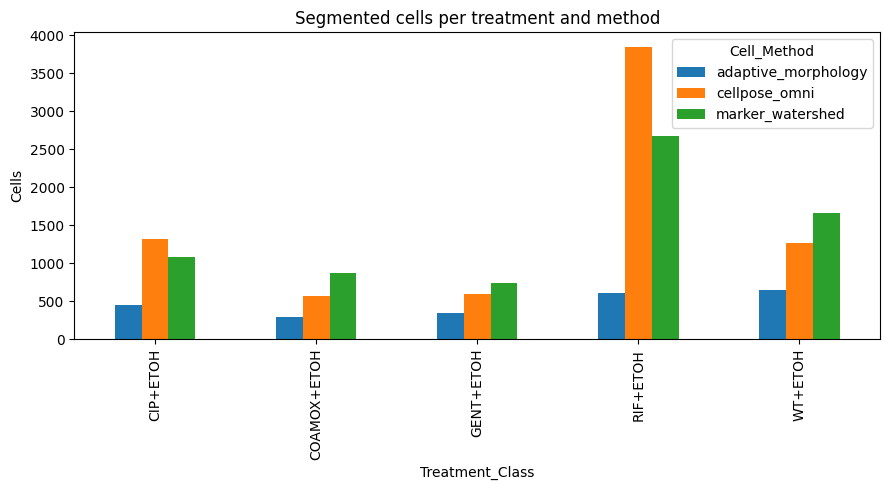

Treatment_Class                       CIP+ETOH  COAMOX+ETOH  GENT+ETOH  \
Cell_Method         Nucleoid_Method                                      
adaptive_morphology blob_log               874          919        651   
                    masked_otsu           1556         1839       1619   
                    masked_watershed     11069        17693      17050   
cellpose_omni       blob_log               623          842        474   
                    masked_otsu           1195         1057        546   
                    masked_watershed      1961         1897        947   
marker_watershed    blob_log               869          879        625   
                    masked_otsu           1322          936        720   
                    masked_watershed      1573         1347        943   

Treatment_Class                       RIF+ETOH  WT+ETOH  
Cell_Method         Nucleoid_Method                      
adaptive_morphology blob_log              8642     2491  
                    masked_otsu           5426     2390  
                    masked_watershed     13824     8136  
cellpose_omni       blob_log              5279     2066  
                    masked_otsu           4711     2248  
                    masked_watershed     10251     3828  
marker_watershed    blob_log              8525     2411  
                    masked_otsu           6158     2329  
                    masked_watershed     12028     3173

In [19]:
# Cell counts per method and class
if non_empty:
    pivot = df_all.pivot_table(index="Treatment_Class", columns="Cell_Method", values="Cell_UID", aggfunc="count", fill_value=0)
    pivot.plot(kind="bar", figsize=(9, 5), title="Segmented cells per treatment and method")
    plt.ylabel("Cells"); plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "qc" / "cells_per_method_and_class.png", dpi=200)
    plt.show()

    nuc_all = pd.concat([pd.DataFrame(nuc_tables[cm]) for cm in CELL_METHODS if nuc_tables[cm]], ignore_index=True)
    display(nuc_all.pivot_table(index=["Cell_Method", "Nucleoid_Method"], columns="Treatment_Class",
                                values="Nucleoid_UID", aggfunc="count", fill_value=0))

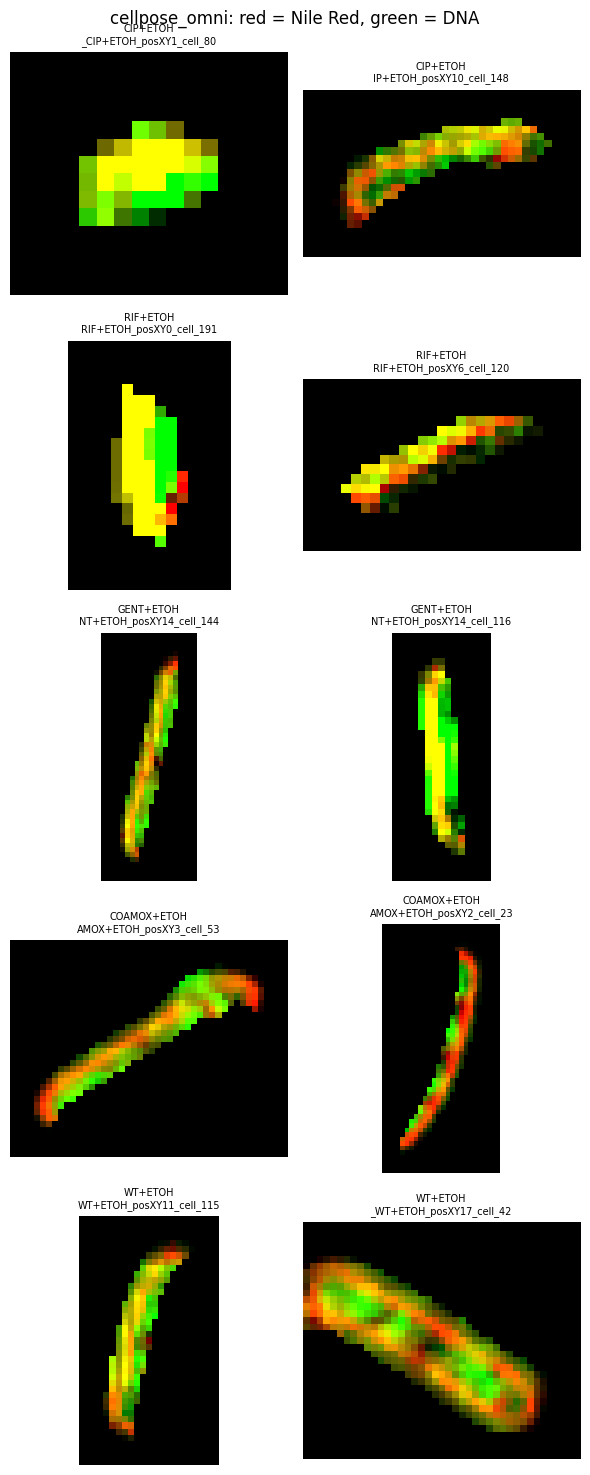

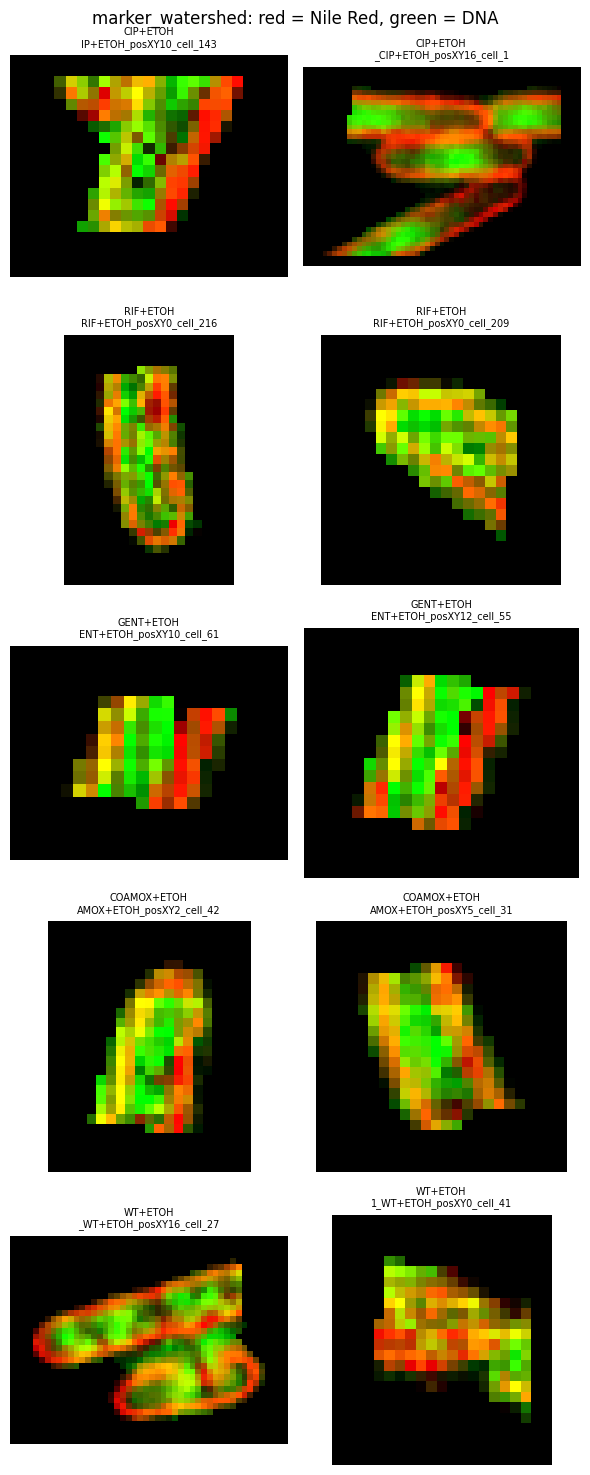

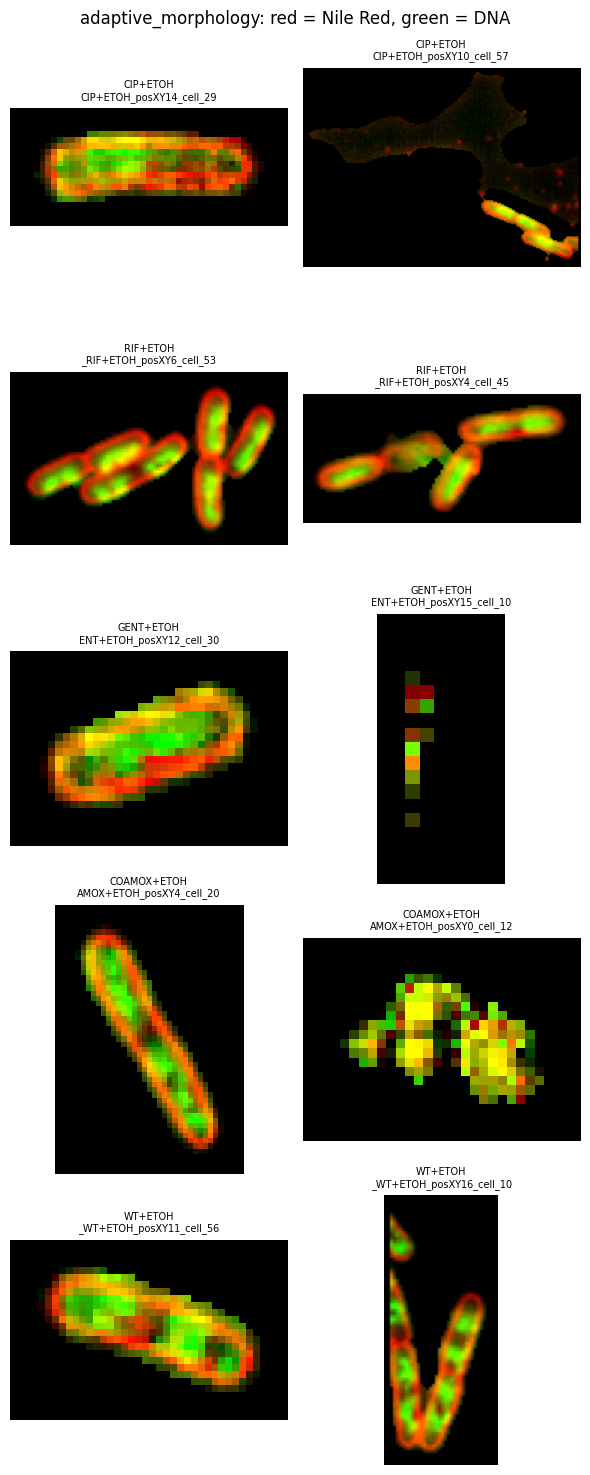

In [20]:
def show_sample_grid(cell_method, n_per_class=2):
    base = OUTPUT_DIR / "individual_cells" / cell_method
    fig, axes = plt.subplots(len(CLASSES), n_per_class, figsize=(3 * n_per_class, 3 * len(CLASSES)), squeeze=False)
    for i, treatment in enumerate(CLASSES):
        files = sorted((base / treatment).glob("*.png"))
        picks = random.sample(files, min(n_per_class, len(files)))
        for j in range(n_per_class):
            ax = axes[i][j]; ax.axis("off")
            if j < len(picks):
                ax.imshow(plt.imread(picks[j])); ax.set_title(f"{treatment}\n{picks[j].stem[-24:]}", fontsize=7)
    fig.suptitle(f"{cell_method}: red = Nile Red, green = DNA", fontsize=12)
    plt.tight_layout(); plt.show()

for cm in CELL_METHODS:
    show_sample_grid(cm)

In [26]:
import shutil, zipfile

GT_ZIP = Path("/content/drive/MyDrive/HRG Projects/Research/Mini Segments.zip")
GT_RAW = Path("/content/gt_raw")

# 1) unzip (skipped if already extracted in this session)
if not GT_RAW.exists():
    GT_RAW.mkdir(parents=True)
    with zipfile.ZipFile(GT_ZIP) as z:
        z.extractall(GT_RAW)

# 2) index every mask by filename stem (works whatever the folder depth inside the zip)
gt_index = {p.stem: p for p in GT_RAW.rglob("*.tif*")}
print("Annotation files found:", len(gt_index))

# 3) copy the matching masks into /content/ground_truth/<class>/<image_name>.tif
found, missing = 0, []
for t in CLASSES:
    (GROUND_TRUTH_DIR / t).mkdir(parents=True, exist_ok=True)
    for img in (INPUT_DIR / t).glob("*.tif*"):
        if img.stem in gt_index:
            shutil.copy(gt_index[img.stem], GROUND_TRUTH_DIR / t / f"{img.stem}.tif")
            found += 1
        else:
            missing.append(img.stem)

print(f"Images with ground truth: {found} | without: {len(missing)}")
if missing:
    print("Example image name :", missing[0])
    print("Example mask name  :", next(iter(gt_index), None))

shutil.rmtree(GT_RAW)      # free disk space, the needed masks are already copied

Annotation files found: 250
Images with ground truth: 250 | without: 0


## 12. Segmentation evaluation against ground truth (optional)
Runs for **every cell method** if `GROUND_TRUTH_DIR/<class>/<image_name>.tif` instance masks exist.
* **Jaccard Index** at each IoU threshold = TP / (TP + FP + FN), with one-to-one Hungarian matching.
* Reported curve is **pooled** over all images (sum TP/FP/FN first, then ratio), so images with more cells count proportionally.
* `Segmentation_Error_Rate` = (FP + FN) / GT cells × 100 at IoU ≥ 0.50.

,Mean_Matched_IoU@0.5,Percent_GT_IoU>=0.80,Segmentation_Error_Rate
Cell_Method,,,
adaptive_morphology,0.827279,33.176718,76.641855
cellpose_omni,0.634082,10.312770,135.652228
marker_watershed,0.657475,7.179528,193.536697


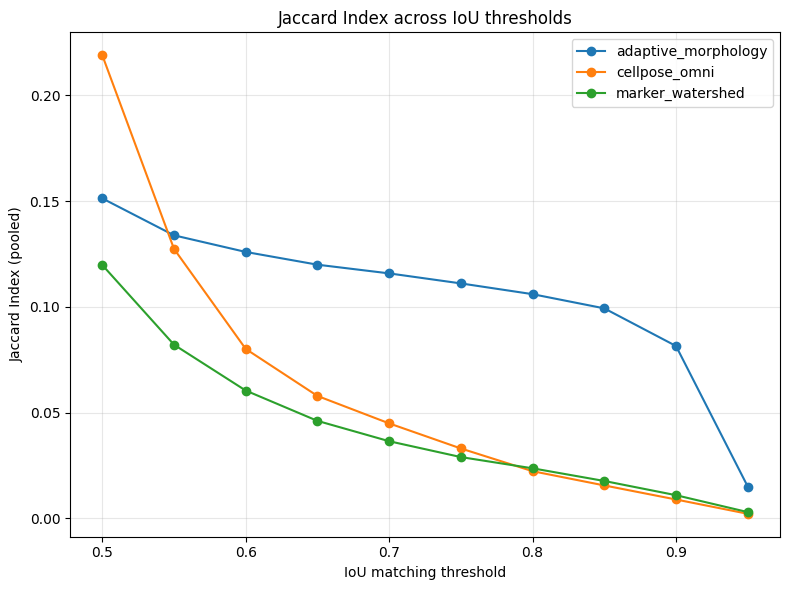

In [28]:
def iou_matrix(gt, pred):
    """IoU between every GT and predicted instance (rows = GT, cols = pred) via one bincount."""
    gt, _, _ = relabel_sequential(np.asarray(gt).astype(np.int64))
    pred, _, _ = relabel_sequential(np.asarray(pred).astype(np.int64))
    n_gt, n_pred = int(gt.max()), int(pred.max())
    if n_gt == 0 or n_pred == 0:
        return np.zeros((n_gt, n_pred))
    overlap = np.bincount((gt.ravel() * (n_pred + 1) + pred.ravel()),
                          minlength=(n_gt + 1) * (n_pred + 1)).reshape(n_gt + 1, n_pred + 1).astype(np.float64)
    gt_area, pred_area = overlap[1:, :].sum(1), overlap[:, 1:].sum(0)
    inter = overlap[1:, 1:]
    return inter / (gt_area[:, None] + pred_area[None, :] - inter)


def evaluate_pair(pred, gt):
    iou = iou_matrix(gt, pred)
    n_gt, n_pred = iou.shape
    if n_gt and n_pred:
        r, c = linear_sum_assignment(-iou)
        matched = iou[r, c]
    else:
        matched = np.array([])

    rows = []
    for t in IOU_THRESHOLDS:
        tp = int((matched >= t).sum())
        rows.append({"IoU_Threshold": t, "TP": tp, "FP": n_pred - tp, "FN": n_gt - tp})

    tp50 = int((matched >= 0.5).sum())
    summary = {
        "GT_Cells": n_gt, "Pred_Cells": n_pred, "Matched_Cells@0.5": tp50,
        "Mean_Matched_IoU@0.5": float(matched[matched >= 0.5].mean()) if tp50 else 0.0,
        "Percent_GT_IoU>=0.80": 100.0 * (matched >= PRIMARY_IOU_THRESHOLD).sum() / n_gt if n_gt else np.nan,
        "Segmentation_Error_Rate": 100.0 * ((n_pred - tp50) + (n_gt - tp50)) / n_gt if n_gt else np.nan,
    }
    return summary, rows


eval_summary, eval_thresholds = [], []
for cm in CELL_METHODS:
    for treatment in CLASSES:
        gt_dir = GROUND_TRUTH_DIR / treatment
        if not gt_dir.exists():
            continue
        for pred_path in sorted((OUTPUT_DIR / "masks" / "cells" / cm / treatment).glob("*_cellmask.tif")):
            fname = pred_path.name.replace("_cellmask.tif", "")
            gt_path = gt_dir / f"{fname}.tif"
            if not gt_path.exists():
                print(f"GT missing: {fname}"); continue
            pred, gt = tifffile.imread(str(pred_path)), tifffile.imread(str(gt_path))
            if pred.shape != gt.shape:
                print(f"Shape mismatch, skipped: {fname}"); continue
            summ, rows = evaluate_pair(pred, gt)
            meta = {"Cell_Method": cm, "Treatment_Class": treatment, "Image_ID": fname}
            eval_summary.append({**meta, **summ})
            eval_thresholds.extend({**meta, **r} for r in rows)

if eval_summary:
    ev = pd.DataFrame(eval_summary)
    ev.to_csv(OUTPUT_DIR / "metrics" / "segmentation_evaluation_per_image.csv", index=False)
    display(ev.groupby("Cell_Method")[["Mean_Matched_IoU@0.5", "Percent_GT_IoU>=0.80", "Segmentation_Error_Rate"]].mean())

    th = pd.DataFrame(eval_thresholds).groupby(["Cell_Method", "IoU_Threshold"])[["TP", "FP", "FN"]].sum().reset_index()
    th["Jaccard_Index"] = th["TP"] / (th["TP"] + th["FP"] + th["FN"]).replace(0, np.nan)
    th.to_csv(OUTPUT_DIR / "metrics" / "jaccard_vs_iou_threshold.csv", index=False)

    plt.figure(figsize=(8, 6))
    for cm, g in th.groupby("Cell_Method"):
        plt.plot(g["IoU_Threshold"], g["Jaccard_Index"], marker="o", label=cm)
    plt.xlabel("IoU matching threshold"); plt.ylabel("Jaccard Index (pooled)")
    plt.title("Jaccard Index across IoU thresholds"); plt.grid(alpha=0.3); plt.legend(); plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "metrics" / "jaccard_vs_iou_threshold.png", dpi=200)
    plt.show()
else:
    print("No ground-truth masks found: evaluation skipped.")

## 13. Save run configuration, zip and download

In [29]:
run_config = {
    "created_at": datetime.now().isoformat(),
    "input_dir": str(INPUT_DIR), "classes": CLASSES, "pixel_size_um": PIXEL_SIZE_UM,
    "cell_methods": CELL_METHODS, "nucleoid_methods": NUC_METHODS,
    "cellpose_omni": {"model": OMNI_MODEL_NAME, "use_dna_channel": OMNI_USE_DNA_CHANNEL, "min_size": OMNI_MIN_SIZE,
                 "mask_threshold": OMNI_MASK_THRESHOLD, "flow_threshold": OMNI_FLOW_THRESHOLD},
    "min_cell_area_px": MIN_CELL_AREA_PX, "nuc_min_area_px": NUC_MIN_AREA_PX, "glcm_levels": GLCM_LEVELS,
    "iou_thresholds": IOU_THRESHOLDS, "seed": SEED, "max_images_per_class": MAX_IMAGES_PER_CLASS,
    "images_failed": len(failed),
    "note": "Intensities/texture computed from RAW channels; enhanced PNGs are visualization only.",
}
(OUTPUT_DIR / "logs" / "run_configuration.json").write_text(json.dumps(run_config, indent=2, default=str))

DRIVE_OUT = Path("/content/drive/MyDrive/HRG Projects/Research/results") / CELL_METHODS[0]
DRIVE_OUT.mkdir(parents=True, exist_ok=True)

for sub in ["tables", "metrics", "qc", "logs"]:                 # small files: copied as-is
    shutil.copytree(OUTPUT_DIR / sub, DRIVE_OUT / sub, dirs_exist_ok=True)

shutil.make_archive(str(DRIVE_OUT / "images_and_masks"), "zip", OUTPUT_DIR)   # zip written straight to Drive
print("Saved to", DRIVE_OUT)

Saved to /content/drive/MyDrive/HRG Projects/Research/results/cellpose_omni


In [31]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

RES = Path("/content/drive/MyDrive/HRG Projects/Research/results")

per_image = pd.concat([pd.read_csv(p) for p in RES.glob("*/metrics/segmentation_evaluation_per_image.csv")], ignore_index=True)
ji        = pd.concat([pd.read_csv(p) for p in RES.glob("*/metrics/jaccard_vs_iou_threshold.csv")], ignore_index=True)

In [32]:
# sanity check: every method must be scored on the same images
per_image.groupby("Cell_Method")["Image_ID"].nunique()

,Image_ID
Cell_Method,
adaptive_morphology,50
cellpose_omni,50
marker_watershed,50


In [33]:
# 1) headline table
cols = ["Mean_Matched_IoU@0.5", "Percent_GT_IoU>=0.80", "Segmentation_Error_Rate"]
per_image.groupby("Cell_Method")[cols].mean().round(3)

,Mean_Matched_IoU@0.5,Percent_GT_IoU>=0.80,Segmentation_Error_Rate
Cell_Method,,,
adaptive_morphology,0.827,33.177,76.642
cellpose_omni,0.634,10.313,135.652
marker_watershed,0.657,7.180,193.537


In [34]:
ji_table = ji.pivot(index="IoU_Threshold", columns="Cell_Method", values="Jaccard_Index")
ji_table.round(3)

Cell_Method,adaptive_morphology,cellpose_omni,marker_watershed
IoU_Threshold,,,
0.50,0.151,0.219,0.120
0.55,0.134,0.127,0.082
0.60,0.126,0.080,0.060
0.65,0.120,0.058,0.046
0.70,0.116,0.045,0.036
0.75,0.111,0.033,0.029
0.80,0.106,0.022,0.024
0.85,0.099,0.016,0.018
0.90,0.082,0.009,0.011


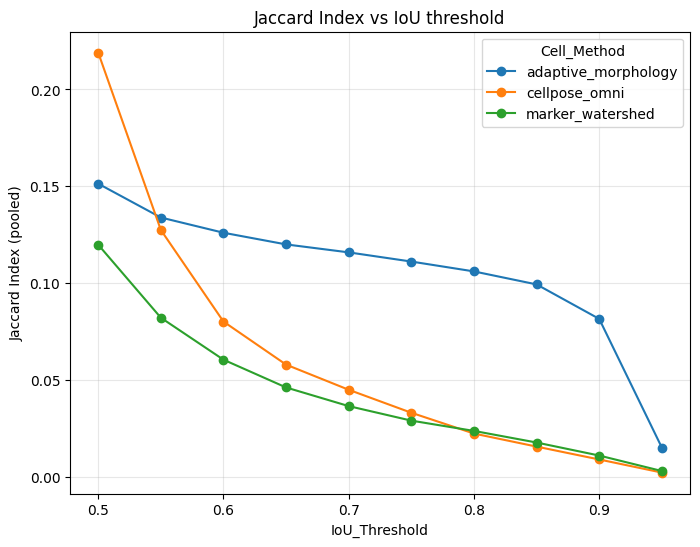

In [35]:
ji_table.plot(marker="o", figsize=(8, 6), title="Jaccard Index vs IoU threshold")
plt.ylabel("Jaccard Index (pooled)")
plt.grid(alpha=0.3)
plt.show()

In [36]:
per_image.pivot_table(index="Treatment_Class", columns="Cell_Method",
                            values="Segmentation_Error_Rate", aggfunc="mean").round(1)

Cell_Method,adaptive_morphology,cellpose_omni,marker_watershed
Treatment_Class,,,
CIP+ETOH,85.0,188.1,178.7
COAMOX+ETOH,37.2,133.2,304.2
GENT+ETOH,55.1,112.1,185.3
RIF+ETOH,109.3,132.7,139.8
WT+ETOH,96.7,112.1,159.7


In [37]:
cells = pd.concat([pd.read_csv(p) for p in RES.glob("*/tables/*_cells.csv") if "all_methods" not in p.name], ignore_index=True)
cells.groupby(["Cell_Method", "Treatment_Class"])[["Area_um2", "Length_um", "Width_um", "Aspect_Ratio"]].mean().round(3)

Area_um2  Length_um  Width_um  \
Cell_Method         Treatment_Class                                  
adaptive_morphology CIP+ETOH           20.793      4.321     1.856   
                    COAMOX+ETOH        34.299      5.111     2.000   
                    GENT+ETOH          29.617      4.207     1.854   
                    RIF+ETOH           10.855      4.243     2.050   
                    WT+ETOH            12.504      4.162     1.813   
cellpose_omni       CIP+ETOH            0.800      2.124     0.526   
                    COAMOX+ETOH         1.090      3.079     0.495   
                    GENT+ETOH           0.946      2.445     0.529   
                    RIF+ETOH            1.014      2.309     0.599   
                    WT+ETOH             1.212      2.633     0.615   
marker_watershed    CIP+ETOH            1.035      1.364     0.866   
                    COAMOX+ETOH         0.726      1.230     0.739   
                    GENT+ETOH           0.822      1.289     0.786   
                    RIF+ETOH            2.018      1.857     1.192   
                    WT+ETOH             0.992      1.399     0.838   

                                     Aspect_Ratio  
Cell_Method         Treatment_Class                
adaptive_morphology CIP+ETOH                3.056  
                    COAMOX+ETOH             3.807  
                    GENT+ETOH               3.054  
                    RIF+ETOH                2.467  
                    WT+ETOH                 3.005  
cellpose_omni       CIP+ETOH                4.337  
                    COAMOX+ETOH             6.409  
                    GENT+ETOH               4.947  
                    RIF+ETOH                4.126  
                    WT+ETOH                 4.683  
marker_watershed    CIP+ETOH                1.584  
                    COAMOX+ETOH             1.687  
                    GENT+ETOH               1.661  
                    RIF+ETOH                1.628  
                    WT+ETOH                 1.687